# HelioLinC: Linking Asteroid Detections by Guessing Their Distance

*Matthew Payne*

A wide-field survey sees each asteroid as a *tracklet*: two or more detections taken within an hour or so, which give a position on the sky and a rate of motion. To find a new asteroid's orbit, its tracklets from different nights must first be recognised as belonging to the same object. This is the *linking problem*. With hundreds of asteroids per square degree near the ecliptic, and every tracklet compatible with a huge range of possible distances, checking every combination of tracklets is hopeless.

This notebook reproduces, on a simulated survey of real asteroid orbits, the main ideas and results of

> M. J. Holman, M. J. Payne, P. Blankley, R. Janssen & S. Kuindersma (2018), *HelioLinC: A Novel Approach to the Minor Planet Linking Problem*, AJ **156**, 135. [ADS](https://ui.adsabs.harvard.edu/abs/2018AJ....156..135H/abstract) · [DOI](https://doi.org/10.3847/1538-3881/aad69a)

which we refer to as H18. The key idea: the distance to an asteroid *from the Earth* is unknown and changes quickly, but its distance *from the Sun* changes slowly and lies within a known range. So **guess the heliocentric distance and its rate of change**, transform every tracklet to the Sun's point of view at a common time, and the tracklets of each asteroid pile up in one place, where a fast clustering search can find them.

We will:

1. Simulate a month of survey tracklets in one field at opposition, from the real orbits of about 58,000 known minor planets.
2. Write down the H18 transformation, which turns each tracklet into an "arrow" at a common reference time, for an assumed heliocentric distance and radial velocity.
3. Follow one asteroid, (10606) Crocco, through the transformation, and measure how sensitive its cluster of arrows is to the two assumed quantities.
4. Cluster the arrows of the whole field with a KD-tree, and tune the two clustering hyperparameters against the known identities of the simulated tracklets.
5. Look at near-Earth objects, Trojans and more distant objects, which the standard main-belt search partly recovers.
6. Measure how the running time grows with the number of tracklets.
7. Go one step beyond the paper and add false tracklets.

Figures are numbered within this notebook; figures of H18 are always called "H18 Figure".

**Requirements:** `numpy`, `scipy` and `matplotlib`.

**Run time:** about three minutes on a laptop.

In [1]:
import time

import matplotlib.pyplot as plt
import numpy as np

import heliolinc as hl   # helper module in this folder: orbits, the simulated survey, the H18 transformation and clustering

NAMES, ORBITS, META = hl.load_orbits("data/orbits.csv.gz")
CLASS = hl.classify(ORBITS["a"], ORBITS["e"])
DEG = np.pi / 180
print(f"{len(NAMES)} orbits from MPCORB; epoch JD {ORBITS['epoch'][0]:.1f}")
print({c: int((CLASS == c).sum()) for c in ["MBA", "NEO", "Hilda", "Trojan", "Centaur", "TNO", "Other"]})

58149 orbits from MPCORB; epoch JD 2461200.5
{'MBA': 56827, 'NEO': 426, 'Hilda': 273, 'Trojan': 562, 'Centaur': 12, 'TNO': 25, 'Other': 24}


## 1. A month of tracklets

### 1.1 The orbits

The orbits are real: an extract of [MPCORB](https://minorplanetcenter.net/iau/MPCORB.html), the Minor Planet Center's orbit file, made by `tools/fetch_heliolinc_orbits.py`. It keeps every object that could appear in our survey field during the month we simulate, and that is brighter than magnitude 22.5 at some time in that month. The coarse dynamical classes printed above come from simple cuts in semi-major axis $a$ and perihelion distance $q$ (NEO: $q < 1.3$ au; MBA: $1.8 < a < 3.7$ au; Hilda: $3.7$–$4.2$; Trojan: $5.05$–$5.35$; Centaur: $5.5$–$30.1$; TNO: $a > 30.1$ au).

### 1.2 The survey

The observations are simulated. The real data in H18 were the MPC's Unnumbered Observations file (for training) and its Isolated Tracklet File (for discovery); here we want to know the true identity of every tracklet, so we make our own, with these simplifications:

* **Motion:** each orbit is propagated as a two-body Keplerian orbit about the Sun from its MPCORB epoch, including light-travel time. Planetary perturbations are left out. Over a 30-day window they would typically shift a main-belt asteroid by an arcsecond or so, far less than the cluster radius we will use (about 200″).
* **Observer:** the Earth–Moon barycentre, from the approximate elements of Standish & Williams (JPL). Diurnal parallax is ignored.
* **Field:** a square, 8° on a side, centred on the ecliptic at opposition on the night of new moon. H18 likewise work in $\pm 15$-day windows centred on new moon.
* **Cadence:** the field is observed every third night from 12 nights before new moon to 12 nights after (9 nights). Each time, every object in the field yields one tracklet of three detections, 20 minutes apart.
* **Brightness:** apparent magnitudes use the IAU $H, G$ system. The chance of detecting an object falls smoothly from 1 to 0 around $V = 21.5$.
* **Astrometric noise:** 0.1″ (Gaussian) in each coordinate of each detection.

In [2]:
T_C = META["window_centre_jd"]                    # the new moon of 2026 June 15
LAM0 = META["opposition_longitude_deg"] * DEG     # ecliptic longitude of opposition
NIGHTS = T_C + np.arange(-12, 13, 3)
FIELD = (LAM0, 0.0, np.tan(4 * DEG))              # centre (longitude, latitude) and half-width

det = hl.simulate_survey(ORBITS, NIGHTS, FIELD)
tr = hl.tracklet_table(det)
FINDABLE = hl.findable(tr["obj"], tr["night"])    # objects with tracklets on 3 or more nights
print(f"Window centre JD {T_C:.4f}; opposition at ecliptic longitude {np.degrees(LAM0):.2f} deg")
print(f"{len(det['t'])} detections in {len(tr['obj'])} tracklets of {len(np.unique(tr['obj']))} objects")
print(f"Sky density: {len(np.unique(tr['obj'])) / 64:.0f} objects per square degree over the month")
print(f"{len(FINDABLE)} objects have tracklets on 3 or more nights:",
      {c: int((CLASS[FINDABLE] == c).sum()) for c in ["MBA", "NEO", "Hilda", "Trojan", "Centaur", "TNO"]})

Window centre JD 2461206.6209; opposition at ecliptic longitude 83.69 deg
111843 detections in 37281 tracklets of 11919 objects
Sky density: 186 objects per square degree over the month
6614 objects have tracklets on 3 or more nights: {'MBA': 6522, 'NEO': 25, 'Hilda': 28, 'Trojan': 34, 'Centaur': 1, 'TNO': 2}


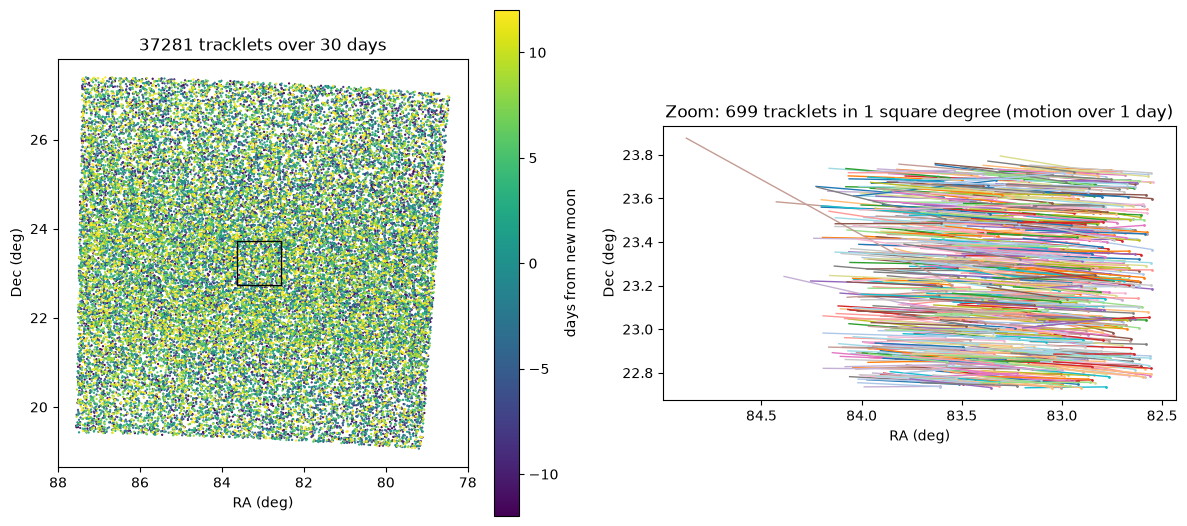

In [3]:
fig, axs = plt.subplots(1, 2, figsize=(12, 5.4))
ra, dec = np.degrees(tr["ra"]), np.degrees(tr["dec"])
ax = axs[0]
sc = ax.scatter(ra, dec, c=tr["t"] - T_C, s=0.4, cmap="viridis", rasterized=True)
ax.set_xlabel("RA (deg)"); ax.set_ylabel("Dec (deg)")
ax.set_title(f"{len(ra)} tracklets over 30 days")
ax.invert_xaxis(); ax.set_aspect(1 / np.cos(np.radians(np.median(dec))))
plt.colorbar(sc, ax=ax, label="days from new moon")
# zoom: a 1-degree box, each tracklet drawn as its motion over one day
ra0, dec0 = np.median(ra), np.median(dec)
box = (np.abs((ra - ra0) * np.cos(np.radians(dec0))) < 0.5) & (np.abs(dec - dec0) < 0.5)
ax.add_patch(plt.Rectangle((ra0 - 0.5 / np.cos(np.radians(dec0)), dec0 - 0.5), 1 / np.cos(np.radians(dec0)), 1,
                           fill=False, color="k", lw=1))
ax = axs[1]
cols = plt.cm.tab20(np.arange(20))
for k in np.flatnonzero(box):
    c = cols[tr["obj"][k] % 20]
    ax.plot([ra[k], ra[k] + np.degrees(tr["dra"][k]) / np.cos(np.radians(dec0))],
            [dec[k], dec[k] + np.degrees(tr["ddec"][k])], color=c, lw=1)
    ax.plot(ra[k], dec[k], ".", color=c, ms=2)
ax.set_xlabel("RA (deg)"); ax.set_ylabel("Dec (deg)")
ax.set_title(f"Zoom: {box.sum()} tracklets in 1 square degree (motion over 1 day)")
ax.invert_xaxis(); ax.set_aspect(1 / np.cos(np.radians(dec0)))
plt.tight_layout(); plt.show()

**Figure 1.** *Left:* every tracklet in the simulated field over the month, coloured by date. *Right:* the tracklets in one square degree, each drawn as the path it would follow in one day and coloured by object (the 20 colours repeat). Many tracklets move in nearly the same direction at nearly the same rate: asteroids near opposition all move retrograde, westward. Which tracklets belong together is far from obvious. This is the linking problem.

## 2. The heliocentric transformation

### 2.1 What a tracklet tells us

An orbit needs six numbers: three of position and three of velocity at some time. A tracklet measures four of them well: two angular positions and two angular rates. The other two, the distance from the observer $\rho$ and its rate $\dot\rho$, are essentially unknown. For a near-Earth object, $\rho$ can change by orders of magnitude in days.

The heliocentric distance $r$, by contrast, changes slowly, and its typical values are known in advance: 2–3.5 au for the main belt, about 5.2 au for Jupiter's Trojans, and so on. H18 therefore *assert* a value of the heliocentric distance and its rate of change, and test each hypothesis in turn.

### 2.2 Arrows

H18 follow the formalism of Bernstein & Khushalani (2000), with the origin at the Sun and a common reference time $t = 0$ for all the tracklets to be linked. The $z$-axis points towards a reference direction on the sky (H18 use the centres of HEALPix tiles; we use the field centre). The $x$-axis points in the direction of increasing ecliptic longitude, and the $y$-axis completes a right-handed set. In terms of an object's heliocentric position $(x_0, y_0, z_0)$ and velocity $(\dot x_0, \dot y_0, \dot z_0)$ at the reference time, H18 Eq. (4) is

$$\alpha \equiv \frac{x_0}{z_0},\quad \beta \equiv \frac{y_0}{z_0},\quad \gamma \equiv \frac{1}{z_0},\qquad
\dot\alpha \equiv \frac{\dot x_0}{z_0},\quad \dot\beta \equiv \frac{\dot y_0}{z_0},\quad \dot\gamma \equiv \frac{\dot z_0}{z_0}.$$

So $\alpha, \beta$ are the object's angular position as seen from the Sun, $\dot\alpha, \dot\beta$ its angular rates, $\gamma$ is (nearly) the inverse of its heliocentric distance, and $\dot\gamma$ is a scaled radial velocity. (The dotted quantities are velocities divided by $z_0$, not time derivatives.)

An observer at $(x_E, y_E, z_E)$ sees the object at the tangent-plane angles $\theta_x = (x - x_E)/(z - z_E)$ and $\theta_y = (y - y_E)/(z - z_E)$ (H18 Eq. 1). Write the object's motion as a straight line plus a small gravitational perturbation $\mathbf{g}(t)$ (H18 Eqs. 2, 3). If $\gamma$ and $\dot\gamma$ are assumed, rearranging gives two equations that are *linear* in the four remaining unknowns (H18 Eq. 6):

$$\alpha + \dot\alpha t' = \theta_x\left[1 + \dot\gamma t' + \gamma g_z(t') - \gamma z_E(t)\right] - \gamma g_x(t') + \gamma x_E(t),$$
$$\beta + \dot\beta t' = \theta_y\left[1 + \dot\gamma t' + \gamma g_z(t') - \gamma z_E(t)\right] - \gamma g_y(t') + \gamma y_E(t),$$

where $t' \approx t - 1/(c\gamma)$ corrects the time of observation for the light-travel time. The right-hand sides are the object's angular position *as seen from the Sun*, computed from the observed $\theta_x, \theta_y$ and the known position of the observer. A least-squares fit of a straight line in time to the detections of one tracklet gives $(\alpha, \beta, \dot\alpha, \dot\beta)$: the tracklet's position and motion as seen from the Sun **at the common reference time**. H18 call this an **arrow**.

All the tracklets of one asteroid share the same arrow, up to observational noise and the error in the assumed $\gamma, \dot\gamma$. So they cluster.

### 2.3 Gravity

H18 list five treatments of the gravitational perturbation, from ignoring it to a full $n$-body integration. Like H18, we adopt their second option: keep only the dominant term

$$g_z(t) \approx -\tfrac{1}{2}\sigma t^2,\qquad \sigma = GM_\odot\gamma^3,$$

which depends only on the assumed $\gamma$. This is the component of the Sun's pull along the reference direction; the transverse terms are much smaller.

## 3. One asteroid: (10606) Crocco

H18 illustrate the transformation with the main-belt asteroid (10606) Crocco (their Figure 1). We use Crocco's MPCORB orbit and simulate its tracklets with the same nine-night cadence, in a window centred on the new moon of 2027 April 6, ten days after Crocco's opposition on March 27.

In [4]:
I_CROCCO = int(np.flatnonzero(NAMES == "(10606) Crocco")[0])
croc = hl.subset(ORBITS, [I_CROCCO])
T_CR = hl.nearest_new_moon(2461491.5) - 69.2 / 86400      # new moon nearest Crocco's opposition of 2027 March 27
u, r, delta, phase = hl.observe(croc, T_CR)
lam_c, beta_c = np.arctan2(u[0, 1], u[0, 0]), np.arcsin(u[0, 2])
det_c = hl.simulate_survey(croc, T_CR + np.arange(-12, 13, 3), (lam_c, beta_c, np.tan(60 * DEG)), v_limit=30)
tr_c = hl.tracklet_table(det_c)
print(f"Window centre JD {T_CR:.4f}; Crocco at r = {r[0]:.3f} au, Delta = {delta[0]:.3f} au, "
      f"V = {hl.hg_magnitude(croc['H'], croc['G'], r, delta, phase)[0]:.1f}; {len(tr_c['obj'])} tracklets")

G0 = 0.4                                                     # H18's main-belt hypothesis, r = 2.5 au
p_c = hl.prepare(det_c, T_CR, G0)
Z_CROCCO = p_c["frame"][2]
truth = hl.true_arrow(croc, T_CR, p_c["frame"])[0]
print(f"Crocco's true gamma = {truth[4]:.4f} (z0 = {1 / truth[4]:.3f} au), gamma_dot = {truth[5]:.2e} per day")

Window centre JD 2461502.4939; Crocco at r = 3.289 au, Delta = 2.329 au, V = 18.4; 9 tracklets
Crocco's true gamma = 0.3042 (z0 = 3.288 au), gamma_dot = -1.84e-04 per day


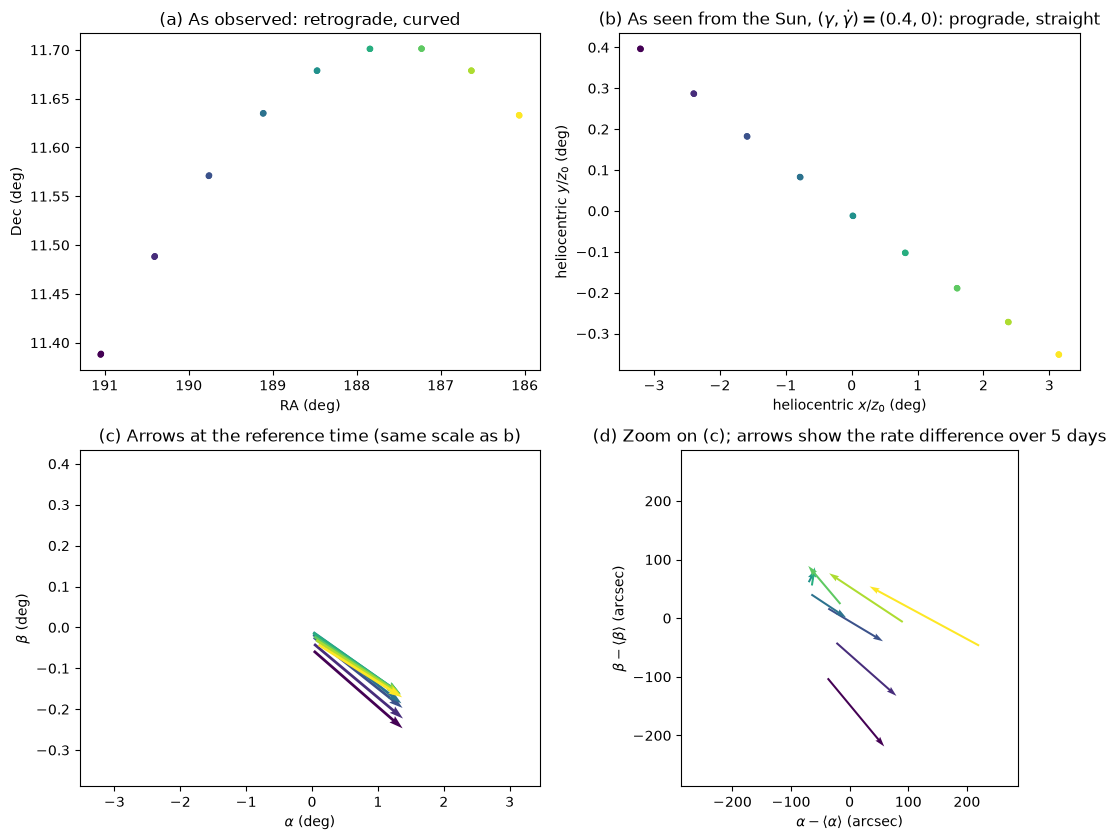

RMS spread of Crocco's arrow positions: 104.2 arcsec (5.1e-04 rad)


In [5]:
ar_c = hl.fit_arrows(p_c, 0.0)
hx, hy, tp = hl.heliocentric_tangent(p_c, 0.0)
fig, axs = plt.subplots(2, 2, figsize=(11, 8.5))
nights_c = np.floor(det_c["t"] - T_CR + 0.5)
ax = axs[0, 0]
ax.scatter(np.degrees(det_c["ra"]), np.degrees(det_c["dec"]), c=nights_c, cmap="viridis", s=12)
ax.invert_xaxis(); ax.set_xlabel("RA (deg)"); ax.set_ylabel("Dec (deg)")
ax.set_title("(a) As observed: retrograde, curved")
ax = axs[0, 1]
ax.scatter(np.degrees(hx), np.degrees(hy), c=nights_c, cmap="viridis", s=12)
ax.set_xlabel(r"heliocentric $x/z_0$ (deg)"); ax.set_ylabel(r"heliocentric $y/z_0$ (deg)")
ax.set_title(r"(b) As seen from the Sun, $(\gamma, \dot\gamma) = (0.4, 0)$: prograde, straight")
lim_x, lim_y = ax.get_xlim(), ax.get_ylim()
ax = axs[1, 0]
ax.quiver(np.degrees(ar_c[:, 0]), np.degrees(ar_c[:, 1]), ar_c[:, 2], ar_c[:, 3], tr_c["t"] - T_CR,
          cmap="viridis", angles="xy", scale_units="xy", scale=1 / np.degrees(5.0), width=0.006)
ax.set_xlim(lim_x); ax.set_ylim(lim_y)
ax.set_xlabel(r"$\alpha$ (deg)"); ax.set_ylabel(r"$\beta$ (deg)")
ax.set_title("(c) Arrows at the reference time (same scale as b)")
ax = axs[1, 1]
m = ar_c.mean(axis=0)
ax.quiver((ar_c[:, 0] - m[0]) / hl.ARCSEC, (ar_c[:, 1] - m[1]) / hl.ARCSEC, ar_c[:, 2] - m[2], ar_c[:, 3] - m[3],
          tr_c["t"] - T_CR, cmap="viridis", angles="xy", scale_units="xy", scale=hl.ARCSEC / 5.0, width=0.006)
ax.set_xlabel(r"$\alpha - \langle\alpha\rangle$ (arcsec)"); ax.set_ylabel(r"$\beta - \langle\beta\rangle$ (arcsec)")
ax.set_title("(d) Zoom on (c); arrows show the rate difference over 5 days")
lim = 1.3 * np.max(np.abs(np.r_[(ar_c[:, 0] - m[0]), (ar_c[:, 1] - m[1])])) / hl.ARCSEC
ax.set_xlim(-lim, lim); ax.set_ylim(-lim, lim); ax.set_aspect("equal")
plt.tight_layout(); plt.show()

spread = np.sqrt(np.mean(np.sum((ar_c[:, :2] - m[:2]) ** 2, axis=1)))
print(f"RMS spread of Crocco's arrow positions: {spread / hl.ARCSEC:.1f} arcsec ({spread:.1e} rad)")

**Figure 2** (after H18 Figure 1). (a) Crocco's detections on the nine nights, coloured by date, as an observer on the Earth sees them: the asteroid moves backwards (retrograde) because the Earth is overtaking it, along a curved path. (b) The same detections transformed with H18 Eq. (6) to the Sun's point of view, assuming $(\gamma, \dot\gamma) = (0.4, 0)$: a steady, prograde, straight-line motion. (c) Each tracklet's fitted arrow, propagated to the common reference time. On the scale of panel (b), the nine arrows sit on top of each other. (d) Zoom: the arrows agree to about 100″, a few ten-thousandths of a radian, even though the assumed distance (2.5 au) is far from Crocco's true 3.3 au. The small trend with date in panel (d) is the signature of that wrong distance.

### 3.1 How well must we guess?

H18 Figure 2 shows how the tightness of a cluster depends on the assumed $\gamma$ and $\dot\gamma$. We can measure this. Below, we refit Crocco's arrows over a range of assumed $\gamma$ (with $\dot\gamma$ at its true value) and of assumed $\dot\gamma$ (with $\gamma$ at its true value), keeping the reference direction fixed, and plot the spread of the arrows in H18's clustering metric (Eq. 11, Section 5).

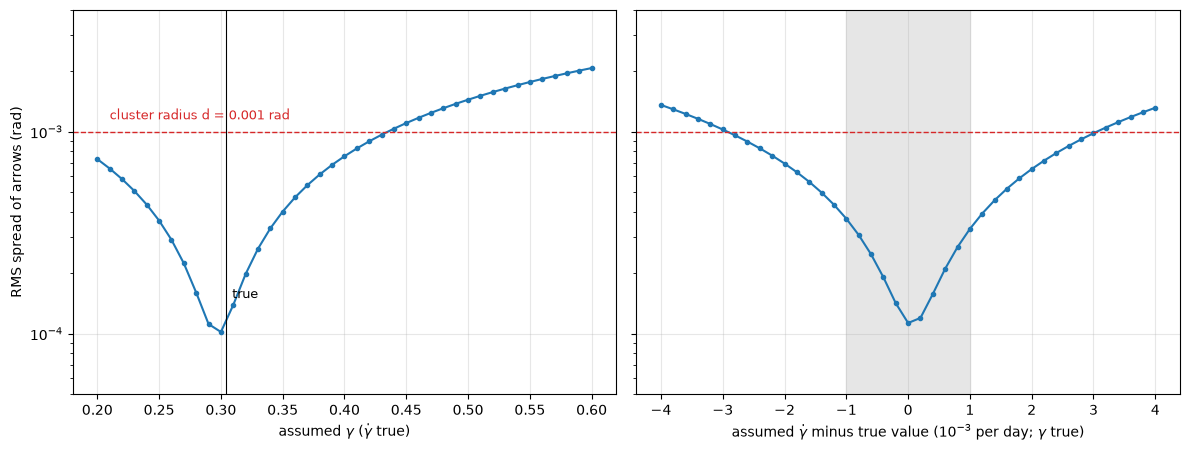

gamma = 0.3: spread 1.0e-04 rad
gamma = 0.35: spread 4.0e-04 rad
gamma = 0.45: spread 1.1e-03 rad
gamma = 0.5: spread 1.4e-03 rad
gamma_dot off by 1e-03: spread 3.3e-04 rad
gamma_dot off by 2e-03: spread 6.5e-04 rad
gamma_dot off by 3e-03: spread 9.8e-04 rad
Main-belt asteroids in the field (5-95%): gamma 0.31 to 0.52, gamma_dot -8.5e-04 to 1.4e-03 per day


In [6]:
D_T = 5.0                                                   # days: H18's adopted velocity weighting (Section 5)

def metric_spread(ar, dt=D_T):
    pts = np.column_stack([ar[:, 0], ar[:, 1], dt * ar[:, 2], dt * ar[:, 3]])
    return np.sqrt(np.mean(np.sum((pts - pts.mean(axis=0)) ** 2, axis=1)))

g_true, gd_true = truth[4], truth[5]
gammas = np.linspace(0.2, 0.6, 41)
s_gamma = [metric_spread(hl.fit_arrows(hl.prepare(det_c, T_CR, g, Z_CROCCO), gd_true)) for g in gammas]
p_true = hl.prepare(det_c, T_CR, g_true, Z_CROCCO)
dgd = np.linspace(-4e-3, 4e-3, 41)
s_gdot = [metric_spread(hl.fit_arrows(p_true, gd_true + x)) for x in dgd]

fig, axs = plt.subplots(1, 2, figsize=(12, 4.6), sharey=True)
for ax, x, s, xl in [(axs[0], gammas, s_gamma, r"assumed $\gamma$ ($\dot\gamma$ true)"),
                     (axs[1], dgd * 1e3, s_gdot, r"assumed $\dot\gamma$ minus true value ($10^{-3}$ per day; $\gamma$ true)")]:
    ax.semilogy(x, s, "o-", ms=3)
    ax.axhline(1e-3, color="C3", ls="--", lw=1)
    ax.set_xlabel(xl); ax.grid(alpha=0.3)
axs[0].axvline(g_true, color="k", lw=0.8); axs[0].text(g_true + 0.005, 1.5e-4, "true", fontsize=9)
axs[1].axvspan(-1, 1, color="0.9", zorder=0)
axs[0].set_ylabel("RMS spread of arrows (rad)")
axs[0].text(0.21, 1.15e-3, "cluster radius d = 0.001 rad", color="C3", fontsize=9)
axs[0].set_ylim(5e-5, 4e-3)
plt.tight_layout(); plt.show()

for g in [0.3, 0.35, 0.45, 0.5]:
    print(f"gamma = {g}: spread {np.interp(g, gammas, s_gamma):.1e} rad")
for x in [1e-3, 2e-3, 3e-3]:
    print(f"gamma_dot off by {x:.0e}: spread {np.interp(x, dgd, s_gdot):.1e} rad")

# For comparison: the true gamma and gamma_dot of the main-belt asteroids in the survey field
frame_field = hl.prepare(det, T_C, G0)["frame"]
mba = FINDABLE[CLASS[FINDABLE] == "MBA"]
ta = hl.true_arrow(hl.subset(ORBITS, mba), T_C, frame_field)
print(f"Main-belt asteroids in the field (5-95%): gamma {np.percentile(ta[:, 4], 5):.2f} to {np.percentile(ta[:, 4], 95):.2f}, "
      f"gamma_dot {np.percentile(ta[:, 5], 5):.1e} to {np.percentile(ta[:, 5], 95):.1e} per day")

**Figure 3** (compare H18 Figure 2). The spread of Crocco's nine arrows, under the H18 metric with $d_t = 5$ days, as the assumed $\gamma$ (left) or $\dot\gamma$ (right) departs from the truth. The dashed line is the cluster radius we will adopt below. The grey band is the largest error in $\dot\gamma$ that H18's grid of five values, spaced by $2\times10^{-3}$ per day, can leave: half the spacing.

Both assumptions are forgiving. Assuming any $\gamma$ from 0.2 to about 0.43 (a factor of two in distance) keeps Crocco's arrows within the cluster radius, and so does any $\dot\gamma$ within $3\times10^{-3}$ per day of the truth. The tolerance to $\gamma$ comes from the degeneracy noted by Bernstein & Khushalani (2000): near opposition, a nearer object with a smaller transverse velocity moves at the same apparent rate as a more distant one with a larger velocity, so an error in $\gamma$ is largely absorbed into $\dot\alpha$.

H18 describe the tightness of clusters as relatively insensitive to $\gamma$ but quite sensitive to $\dot\gamma$. For Crocco, the comparison depends on the units:
- **The paper's grid:** half its $\dot\gamma$ spacing ($10^{-3}$ per day) spreads the arrows by $3\times10^{-4}$ rad, while a 30% error in distance ($\gamma = 0.4$ instead of 0.30) spreads them by $8\times10^{-4}$ rad.
- **The range real orbits span:** for main-belt asteroids in our field, $\gamma$ spans about 0.31–0.52, but $\dot\gamma$ spans only about $-0.9\times10^{-3}$ to $+1.4\times10^{-3}$ per day (5th to 95th percentiles).

So, for Crocco and across the main belt, the larger spread comes from the assumed distance, not from $\dot\gamma$. We do not reproduce the emphasis of H18 Figure 2 in this measure. What matters in practice, and what we do confirm, is H18's conclusion that tight clusters form without fine steps in either parameter: one $\gamma$ and five values of $\dot\gamma$ keep the main belt's clusters within the cluster radius.

## 4. The whole field

### 4.1 Arrows for every tracklet

Now we transform every tracklet in the field with $(\gamma, \dot\gamma) = (0.4, 0)$. To see what happens, we pick the objects whose arrows fall in a small patch of $(\alpha, \beta)$, and plot their tracklets at each stage, coloured by object (H18 Figure 3).

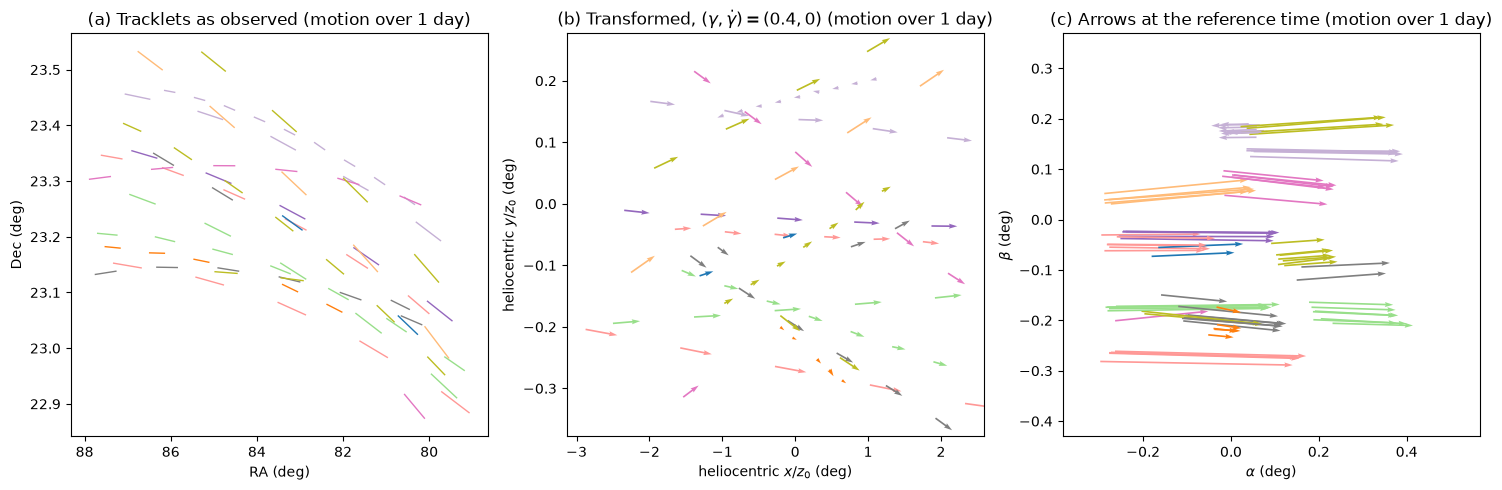

18 objects, 83 tracklets


In [7]:
P0 = hl.prepare(det, T_C, G0)                  # reference direction: the field centre seen from the Sun at 2.5 au
ar0 = hl.fit_arrows(P0, 0.0)
hx, hy, _ = hl.heliocentric_tangent(P0, 0.0)
a_mid, b_mid = np.median(ar0[:, 0]), np.median(ar0[:, 1])
w = 0.25 * DEG
objs = np.unique(tr["obj"][(np.abs(ar0[:, 0] - a_mid) < w) & (np.abs(ar0[:, 1] - b_mid) < w)])
sel = np.isin(tr["obj"], objs)
seld = np.isin(det["obj"], objs)
cols = plt.cm.tab20(np.arange(20))
colour = lambda o: cols[o % 20]

fig, axs = plt.subplots(1, 3, figsize=(15, 5))
ax = axs[0]
for k in np.flatnonzero(sel):
    c = colour(tr["obj"][k])
    ax.plot([np.degrees(tr["ra"][k]), np.degrees(tr["ra"][k] + tr["dra"][k] / np.cos(tr["dec"][k]))],
            [np.degrees(tr["dec"][k]), np.degrees(tr["dec"][k] + tr["ddec"][k])], color=c, lw=1)
ax.invert_xaxis(); ax.set_xlabel("RA (deg)"); ax.set_ylabel("Dec (deg)")
ax.set_title("(a) Tracklets as observed (motion over 1 day)")
ax = axs[1]
n_t = len(tr["obj"])
hxm = np.bincount(det["tracklet"], hx, n_t) / tr["n"]
hym = np.bincount(det["tracklet"], hy, n_t) / tr["n"]
for k in np.flatnonzero(sel):
    ax.quiver(np.degrees(hxm[k]), np.degrees(hym[k]), ar0[k, 2], ar0[k, 3], color=colour(tr["obj"][k]),
              angles="xy", scale_units="xy", scale=1 / np.degrees(1.0), width=0.004)
ax.set_xlabel(r"heliocentric $x/z_0$ (deg)"); ax.set_ylabel(r"heliocentric $y/z_0$ (deg)")
ax.set_title(r"(b) Transformed, $(\gamma, \dot\gamma) = (0.4, 0)$ (motion over 1 day)")
ax = axs[2]
for k in np.flatnonzero(sel):
    ax.quiver(np.degrees(ar0[k, 0]), np.degrees(ar0[k, 1]), ar0[k, 2], ar0[k, 3], color=colour(tr["obj"][k]),
              angles="xy", scale_units="xy", scale=1 / np.degrees(1.0), width=0.004)
ax.set_xlim(np.degrees(a_mid - 1.3 * w), np.degrees(a_mid + 2.5 * w))
ax.set_ylim(np.degrees(b_mid - 1.6 * w), np.degrees(b_mid + 1.6 * w))
ax.set_xlabel(r"$\alpha$ (deg)"); ax.set_ylabel(r"$\beta$ (deg)")
ax.set_title("(c) Arrows at the reference time (motion over 1 day)")
plt.tight_layout(); plt.show()
print(f"{len(objs)} objects, {sel.sum()} tracklets")

**Figure 4** (after H18 Figure 3). The tracklets of the objects whose arrows land in one $0.5° \times 0.5°$ patch, coloured by object. (a) As observed, tracklets of different objects interleave over the whole field, and it is hard to tell which belong together. (b) Transformed to the Sun's point of view, each tracklet now moves prograde, and each object's tracklets lie along one line with parallel motions. (c) Propagated back to the common reference time as arrows, each object's tracklets collapse to a single point and direction: the colours separate into clusters.

### 4.2 Clusters come into focus

The value of $\dot\gamma$ matters. Below, we zoom further in and change only the assumed $\dot\gamma$ (H18 Figure 4).

(192634) 1999 NF60: 7 tracklets, true gamma_dot = 1.33e-03 per day


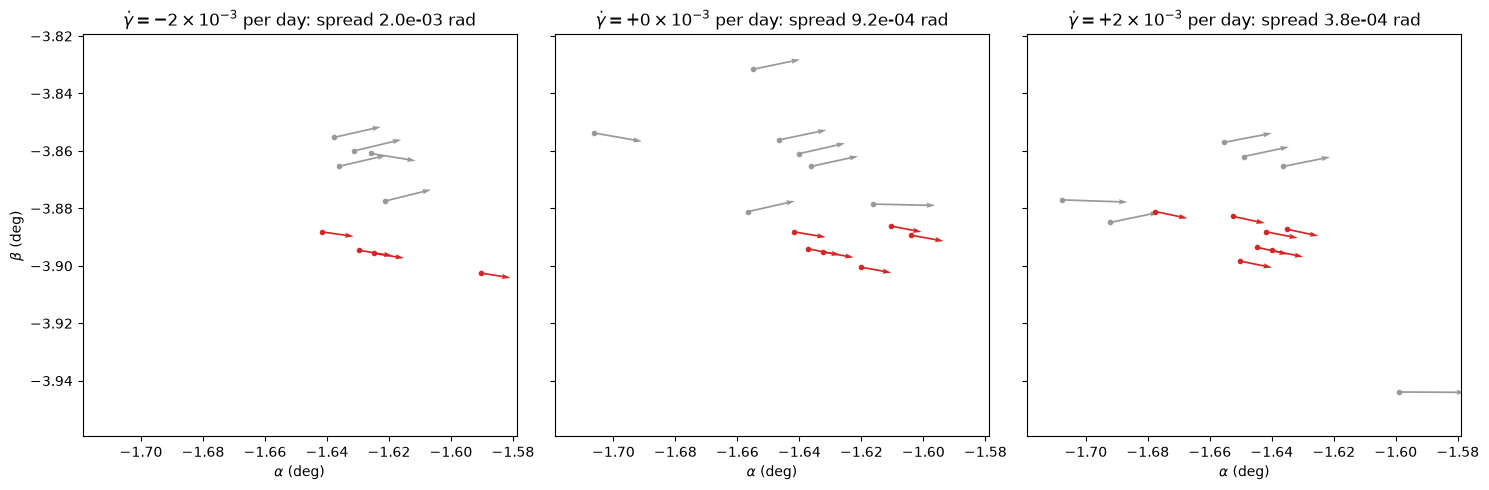

In [8]:
# Follow one main-belt asteroid with a large true gamma_dot and tracklets on many nights
cand = np.array([o for o in FINDABLE[CLASS[FINDABLE] == "MBA"] if np.sum(tr["obj"] == o) >= 7])
gd_cand = hl.true_arrow(hl.subset(ORBITS, cand), T_C, P0["frame"])[:, 5]
o_t = cand[np.argmax(gd_cand)]
mine = tr["obj"] == o_t
print(f"{NAMES[o_t]}: {mine.sum()} tracklets, true gamma_dot = {gd_cand.max():.2e} per day")
fig, axs = plt.subplots(1, 3, figsize=(15, 5), sharex=True, sharey=True)
a_c, b_c = hl.fit_arrows(P0, 2e-3)[mine, :2].mean(axis=0)
w2 = 0.07 * DEG
for ax, gd in zip(axs, [-2e-3, 0.0, 2e-3]):
    ar = hl.fit_arrows(P0, gd)
    near = (np.abs(ar[:, 0] - a_c) < w2) & (np.abs(ar[:, 1] - b_c) < w2)
    for m_, col, z in [(near & ~mine, "0.6", 1), (mine, "C3", 2)]:
        ax.quiver(np.degrees(ar[m_, 0]), np.degrees(ar[m_, 1]), ar[m_, 2], ar[m_, 3], color=col, zorder=z,
                  angles="xy", scale_units="xy", scale=1 / np.degrees(0.05), width=0.004)
        ax.plot(np.degrees(ar[m_, 0]), np.degrees(ar[m_, 1]), "o", color=col, ms=3, zorder=z)
    ax.set_xlim(np.degrees(a_c - w2), np.degrees(a_c + w2)); ax.set_ylim(np.degrees(b_c - w2), np.degrees(b_c + w2))
    sp = metric_spread(ar[mine])
    ax.set_title(rf"$\dot\gamma = {gd * 1e3:+.0f}\times10^{{-3}}$ per day: spread {sp:.1e} rad")
    ax.set_xlabel(r"$\alpha$ (deg)")
axs[0].set_ylabel(r"$\beta$ (deg)")
plt.tight_layout(); plt.show()

**Figure 5** (after H18 Figure 4). A $0.14°$ patch of arrow space around one main-belt asteroid (red, named above), for three assumed values of $\dot\gamma$. Its true $\dot\gamma$ is one of the largest in the field. Grey arrows belong to other objects. Dots mark the arrows' positions and lines their rates over 1.2 hours. Clusters "move in and out of focus", in H18's words. This object's cluster is tightest (spread in each panel title) at $+2\times10^{-3}$, the grid value nearest its true $\dot\gamma$. At the other values it smears out, mostly along its direction of motion; at $-2\times10^{-3}$, two of its seven arrows fall outside the panel.

## 5. Finding the clusters

### 5.1 The algorithm

H18 link tracklets by finding clusters of arrows with a KD-tree. Two arrows are close if

$$d^2 = (\alpha - \alpha')^2 + (\beta - \beta')^2 + d_t^2\left[(\dot\alpha - \dot\alpha')^2 + (\dot\beta - \dot\beta')^2\right] \tag{H18 Eq. 11}$$

is small, where the time $d_t$ weights the rates against the positions. For each arrow, the KD-tree returns all arrows within a radius $d$, and any such group of **three or more** arrows is a candidate cluster. We merge the candidates from all values of $\dot\gamma$ and drop any cluster that is a proper subset of another (H18 Section 5.1). H18 use a dual-tree algorithm; we use SciPy's `cKDTree`, which gives the same neighbours.

Every step is either per tracklet or a tree search, with no loop over pairs or triples of tracklets. H18 show that the whole algorithm scales as $\mathcal{O}(N\log N)$ in the number of tracklets $N$, compared with $\mathcal{O}(N^3)$ for the orbit-fitting step of the Pan-STARRS Moving Object Processing System (MOPS), as given by Jones et al. (2018). We test this in Section 7.

### 5.2 Scoring

Because we simulated the data, we know which object made each tracklet, so we can use H18's three dispositions for a cluster:

* **pure:** all its tracklets come from one object;
* **valid:** three or more tracklets from one object, plus one or more interlopers, which orbit fitting could in principle remove;
* **erroneous:** no object contributes three tracklets.

We count the objects found in at least one pure cluster, the objects found in a pure or valid cluster, and the erroneous clusters. The best possible score is the number of objects with tracklets on three or more nights, printed in Section 1.

### 5.3 Training the hyperparameters

H18 trained the cluster radius $d$ and the velocity weighting $d_t$ on labelled MPC data, using a single $\gamma = 0.4$ and five values of $\dot\gamma$ from $-4\times10^{-3}$ to $4\times10^{-3}$ per day (their Figure 5). We do the same with our simulated field.

65 clusterings in 51 s


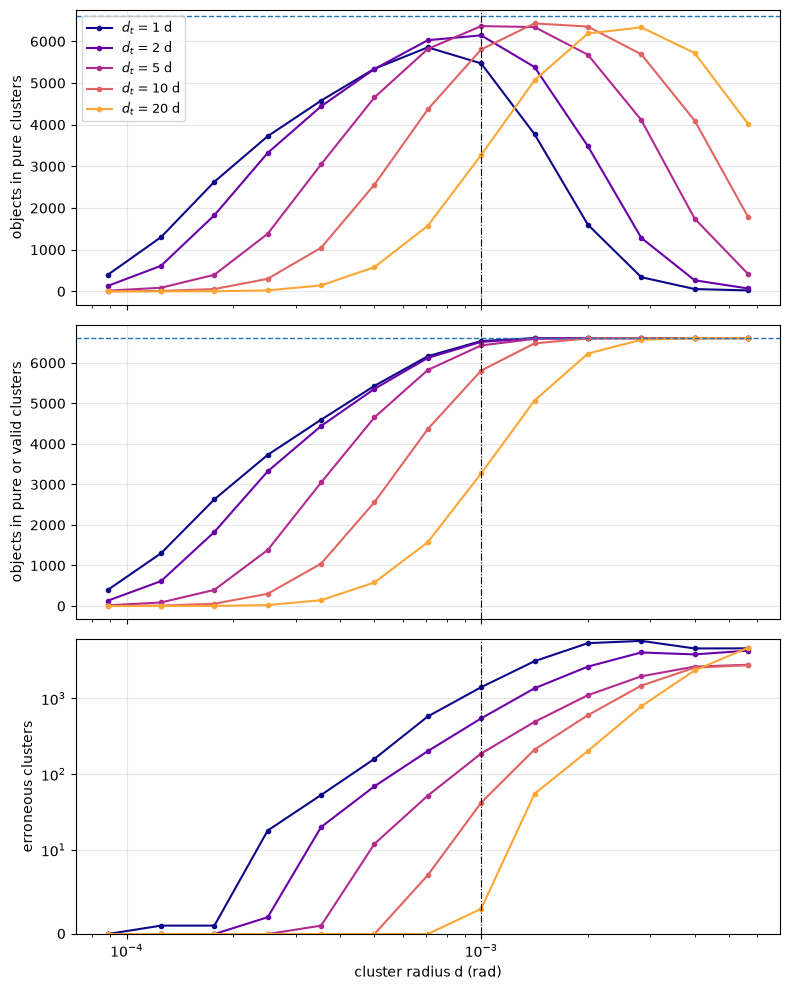

d_t = 5 d, d = 1.0e-03 rad: {'pure_objects': 6366, 'valid_objects': 6431, 'erroneous': 187, 'clusters': 7217} -> 96.3% of findable objects in pure clusters
d_t =    1 d: most objects in pure clusters, 5856, at d = 7.1e-04 rad
d_t =    2 d: most objects in pure clusters, 6144, at d = 1.0e-03 rad
d_t =    5 d: most objects in pure clusters, 6366, at d = 1.0e-03 rad
d_t =   10 d: most objects in pure clusters, 6431, at d = 1.4e-03 rad
d_t =   20 d: most objects in pure clusters, 6337, at d = 2.8e-03 rad


In [9]:
GAMMA_DOTS = np.array([-4e-3, -2e-3, 0.0, 2e-3, 4e-3])     # per day: H18's main-belt grid
D_GRID = 1e-3 * 2.0 ** np.arange(-3.5, 2.6, 0.5)            # cluster radius, radians: 9e-5 to 6e-3, including 1e-3
DTS = [1.0, 2.0, 5.0, 10.0, 20.0]                           # velocity weighting, days

t0 = time.time()
ARROWS = hl.all_arrows(det, T_C, G0, GAMMA_DOTS)
SCAN = {dt: [hl.score(hl.cluster_arrows(ARROWS, d, dt), tr["obj"]) for d in D_GRID] for dt in DTS}
print(f"{len(DTS) * len(D_GRID)} clusterings in {time.time() - t0:.0f} s")

fig, axs = plt.subplots(3, 1, figsize=(8, 10), sharex=True)
for i, dt in enumerate(DTS):
    for ax, key in zip(axs, ["pure_objects", "valid_objects", "erroneous"]):
        ax.plot(D_GRID, [s[key] for s in SCAN[dt]], "o-", ms=3, color=plt.cm.plasma(i / len(DTS)), label=f"$d_t$ = {dt:g} d")
for ax, lab in zip(axs, ["objects in pure clusters", "objects in pure or valid clusters", "erroneous clusters"]):
    ax.set_xscale("log"); ax.set_ylabel(lab); ax.grid(alpha=0.3)
for ax in axs[:2]:
    ax.axhline(len(FINDABLE), color="C0", ls="--", lw=1)
axs[2].set_yscale("symlog", linthresh=10); axs[2].set_ylim(bottom=0)
axs[2].set_xlabel("cluster radius d (rad)")
axs[0].legend(fontsize=9)
for ax in axs:
    ax.axvline(1e-3, color="k", ls="-.", lw=0.8)
plt.tight_layout(); plt.show()

K1 = int(np.argmin(np.abs(D_GRID - 1e-3)))
best = SCAN[5.0][K1]
print(f"d_t = 5 d, d = {D_GRID[K1]:.1e} rad:", best,
      f"-> {best['pure_objects'] / len(FINDABLE):.1%} of findable objects in pure clusters")
for dt in DTS:
    k = int(np.argmax([s["pure_objects"] for s in SCAN[dt]]))
    print(f"d_t = {dt:4.0f} d: most objects in pure clusters, {SCAN[dt][k]['pure_objects']}, at d = {D_GRID[k]:.1e} rad")

**Figure 6** (after H18 Figure 5). Linking performance against the cluster radius $d$, for five values of $d_t$. The dashed line is the number of findable objects. *Top:* objects found in pure clusters. *Middle:* objects found in pure or valid clusters. *Bottom:* erroneous clusters. The dash-dotted line marks the radius we adopt, $d = 10^{-3}$ rad.

The curves have the shape H18 found:

* **Small radii:** only the tightest clusters are found.
* **Growing radius:** more objects are found, until clusters begin to swallow arrows from other objects. Then the number of *pure* clusters falls, while the number of objects in pure or valid clusters levels off at the number of findable objects.
* **Beyond a threshold:** erroneous clusters rise steeply.

For $d_t = 5$ days, the value H18 adopted, about 96% of the findable objects are found in pure clusters at $d = 10^{-3}$ rad.

**One difference from the paper:** H18 adopted $d = 2\times10^{-3}$ rad for their training data; our optimum is half that. The best radius depends on how crowded arrow space is, which differs between data sets. Our simulated field is complete to $V = 21.5$ at opposition on the ecliptic, with every object observed on every night. H18's own data sets show the same dependence. For the Isolated Tracklet File, which has a larger share of tracklets that cannot be linked, they chose a smaller radius, $6\times10^{-4}$ rad.

As in H18, smaller $d_t$ finds more objects at small radii, and larger $d_t$ rejects arrows that are not parallel. H18 explain that the ideal $d_t$ is comparable to the time span of the observations, a few days within one lunation.

### 5.4 The grid of hypotheses

H18 also tried four values of $\gamma$ and a twice-finer grid of $\dot\gamma$ (their Figure 6), and found that both improve completeness, though not dramatically.

done in 106 s


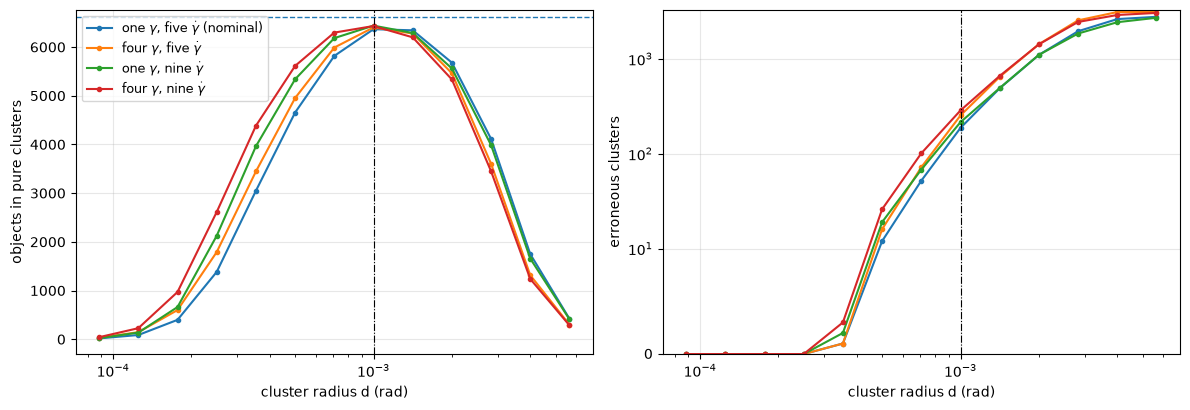

one $\gamma$, five $\dot\gamma$ (nominal)     d = 1.0e-03: pure objects 6366, erroneous 187
four $\gamma$, five $\dot\gamma$              d = 1.0e-03: pure objects 6402, erroneous 253
one $\gamma$, nine $\dot\gamma$               d = 1.0e-03: pure objects 6439, erroneous 215
four $\gamma$, nine $\dot\gamma$              d = 1.0e-03: pure objects 6431, erroneous 286


In [10]:
GRIDS = {
    r"one $\gamma$, five $\dot\gamma$ (nominal)": ([0.4], GAMMA_DOTS),
    r"four $\gamma$, five $\dot\gamma$": ([0.3, 0.35, 0.4, 0.45], GAMMA_DOTS),
    r"one $\gamma$, nine $\dot\gamma$": ([0.4], np.arange(-4e-3, 4.1e-3, 1e-3)),
    r"four $\gamma$, nine $\dot\gamma$": ([0.3, 0.35, 0.4, 0.45], np.arange(-4e-3, 4.1e-3, 1e-3)),
}
t0 = time.time()
GRID_SCAN = {}
for name, (gs, gds) in GRIDS.items():
    arrows = hl.all_arrows(det, T_C, gs, gds, z_dir=P0["frame"][2])
    GRID_SCAN[name] = [hl.score(hl.cluster_arrows(arrows, d, 5.0), tr["obj"]) for d in D_GRID]
print(f"done in {time.time() - t0:.0f} s")

fig, axs = plt.subplots(1, 2, figsize=(12, 4.2), sharex=True)
for i, (name, sc) in enumerate(GRID_SCAN.items()):
    axs[0].plot(D_GRID, [s["pure_objects"] for s in sc], "o-", ms=3, label=name)
    axs[1].plot(D_GRID, [s["erroneous"] for s in sc], "o-", ms=3)
axs[0].axhline(len(FINDABLE), color="C0", ls="--", lw=1)
axs[0].set_ylabel("objects in pure clusters"); axs[1].set_ylabel("erroneous clusters")
axs[1].set_yscale("symlog", linthresh=10); axs[1].set_ylim(bottom=0)
for ax in axs:
    ax.set_xscale("log"); ax.set_xlabel("cluster radius d (rad)"); ax.grid(alpha=0.3); ax.axvline(1e-3, color="k", ls="-.", lw=0.8)
axs[0].legend(fontsize=9)
plt.tight_layout(); plt.show()
k = K1
for name, sc in GRID_SCAN.items():
    print(f"{name:45s} d = {D_GRID[k]:.1e}: pure objects {sc[k]['pure_objects']}, erroneous {sc[k]['erroneous']}")

**Figure 7** (after H18 Figure 6). Objects found in pure clusters (left) and erroneous clusters (right) for four grids of hypotheses, with $d_t = 5$ days. A finer grid finds more objects at the smallest radii, where only an almost exact hypothesis brings a cluster within the radius. At the adopted radius, the gain is small, in line with H18's conclusion: once the grid is fine enough that observational noise, not the grid, sets the size of a cluster, refining it further does not help. More hypotheses also produce more erroneous clusters, because each one is another chance for unrelated arrows to line up.

## 6. Beyond the main belt

### 6.1 Heliocentric rates of motion

Different kinds of object move at different rates as seen from the Sun. H18 (their Figure 9) plot the fitted rates $\dot\alpha, \dot\beta$ from the $(\gamma, \dot\gamma) = (0.4, 0)$ transformation, and propose excluding tracklets that fall in a "main-belt box", $3.5\times10^{-3} < \dot\alpha < 5.5\times10^{-3}$ and $|\dot\beta| < 2\times10^{-3}$ per day, before searching for rarer populations at other distances.

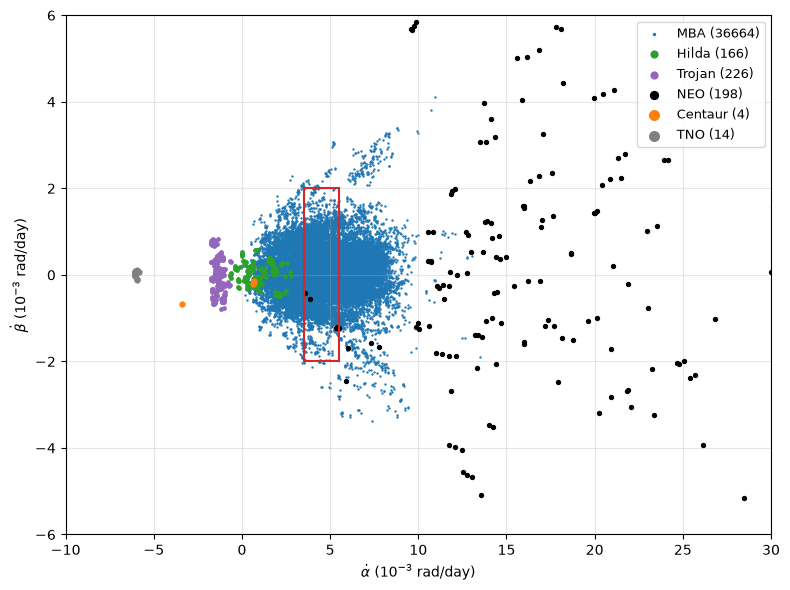

MBA     : 39.4% of 36664 tracklets in the box; alpha_dot 5-95%:   1.89 to   7.41 x 1e-3
Hilda   :  0.0% of   166 tracklets in the box; alpha_dot 5-95%:  -0.31 to   2.23 x 1e-3
Trojan  :  0.0% of   226 tracklets in the box; alpha_dot 5-95%:  -1.69 to  -0.99 x 1e-3
NEO     :  2.5% of   198 tracklets in the box; alpha_dot 5-95%:   9.52 to  41.65 x 1e-3
Centaur :  0.0% of     4 tracklets in the box; alpha_dot 5-95%:  -2.79 to   0.70 x 1e-3
TNO     :  0.0% of    14 tracklets in the box; alpha_dot 5-95%:  -6.09 to  -5.89 x 1e-3
MBA tracklets with true gamma 0.25-0.33 (r = 3.0-4.0 au): median alpha_dot 1.92 x 1e-3
MBA tracklets with true gamma 0.33-0.4 (r = 2.5-3.0 au): median alpha_dot 3.44 x 1e-3
MBA tracklets with true gamma 0.4-0.45 (r = 2.2-2.5 au): median alpha_dot 4.89 x 1e-3
MBA tracklets with true gamma 0.45-0.6 (r = 1.7-2.2 au): median alpha_dot 6.61 x 1e-3


In [11]:
cls_t = CLASS[tr["obj"]]
BOX = (ar0[:, 2] > 3.5e-3) & (ar0[:, 2] < 5.5e-3) & (np.abs(ar0[:, 3]) < 2e-3)
fig, ax = plt.subplots(figsize=(8, 6))
style = {"MBA": ("C0", 0.5, 1), "Hilda": ("C2", 6, 3), "Trojan": ("C4", 6, 3), "NEO": ("k", 8, 4),
         "Centaur": ("C1", 12, 5), "TNO": ("0.5", 12, 5)}
for c, (col, s, z) in style.items():
    m = cls_t == c
    ax.scatter(ar0[m, 2] * 1e3, ar0[m, 3] * 1e3, s=s, color=col, label=f"{c} ({m.sum()})", zorder=z, rasterized=True)
ax.add_patch(plt.Rectangle((3.5, -2), 2, 4, fill=False, color="C3", lw=1.5, zorder=6))
ax.set_xlim(-10, 30); ax.set_ylim(-6, 6)
ax.set_xlabel(r"$\dot\alpha$ ($10^{-3}$ rad/day)"); ax.set_ylabel(r"$\dot\beta$ ($10^{-3}$ rad/day)")
ax.legend(markerscale=2, fontsize=9); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()
for c in style:
    m = cls_t == c
    if m.any():
        print(f"{c:8s}: {BOX[m].mean():5.1%} of {m.sum():5d} tracklets in the box; "
              f"alpha_dot 5-95%: {np.percentile(ar0[m, 2], 5) * 1e3:6.2f} to {np.percentile(ar0[m, 2], 95) * 1e3:6.2f} x 1e-3")
m = cls_t == "MBA"
g_mba = hl.true_arrow(hl.subset(ORBITS, tr["obj"][m]), T_C, P0["frame"])[:, 4]
for lo, hi in [(0.25, 0.33), (0.33, 0.4), (0.4, 0.45), (0.45, 0.6)]:
    s_ = (g_mba >= lo) & (g_mba < hi)
    print(f"MBA tracklets with true gamma {lo}-{hi} (r = {1 / hi:.1f}-{1 / lo:.1f} au): median alpha_dot {np.median(ar0[m][s_, 2]) * 1e3:.2f} x 1e-3")

**Figure 8** (after H18 Figure 9). Heliocentric rates of every tracklet in the field for $(\gamma, \dot\gamma) = (0.4, 0)$, coloured by class (numbers of tracklets in brackets). The red box is H18's main-belt box.

The populations separate cleanly:
- **NEOs** move fastest. They are close to the Earth and moving quickly, so the $\gamma = 0.4$ transformation leaves much of their apparent motion in place.
- **Hildas and Trojans**, farther out, move slowly.
- **TNOs** have rates dominated by the Earth's motion, which the $\gamma = 0.4$ transformation removes correctly only for objects near 2.5 au.

**One difference from the paper:** in our field, the box contains fewer than half of the main-belt tracklets; H18 describe it as holding the majority. Our main-belt rates spread more widely along $\dot\alpha$, and the spread follows distance: asteroids nearer than 2.5 au appear at higher $\dot\alpha$, and farther ones at lower $\dot\alpha$ (printed below). Part of this is the real range of orbital speeds across the belt. Part is the degeneracy of Section 3.1, which shifts $\dot\alpha$ when $\gamma$ is wrong. How much of the belt falls in a fixed box therefore depends on the mix of distances in the data. The box still excludes almost none of the other populations.

### 6.2 Recovering other populations

H18 (their Figures 7 and 8) found that the standard main-belt search also recovers about half of the NEOs and the majority of Trojans, Centaurs and TNOs, and that searches tailored to each population recover more. Below we run the standard search, then tailored searches:

* **NEOs:** $\gamma = 0.5$–$0.9$, as in H18, with a wider radius.
* **Hildas, Trojans and TNOs:** $\gamma$ at the population's typical distance (0.26, 0.19 and 0.025).

For the tailored searches, the $\dot\gamma$ grid is scaled by $(\gamma/0.4)^{3/2}$, as orbital speeds about the Sun scale. These are our choices: H18's grids for the outer populations are not given in the paper's text. Following H18, the tailored searches use only the tracklets **outside** the main-belt box.

In [12]:
def found_pure(clusters, objs_of_tracklet):
    out = set()
    for c in clusters:
        o = np.unique(objs_of_tracklet[list(c)])
        if o.size == 1:
            out.add(int(o[0]))
    return out

std = found_pure(hl.cluster_arrows(ARROWS, 1e-3, D_T), tr["obj"])
outside = hl.select_tracklets(det, ~BOX)
obj_out = tr["obj"][~BOX]
scaled = lambda g: GAMMA_DOTS * (g / 0.4) ** 1.5
TAILORED = {"NEO": (np.arange(0.5, 0.91, 0.1), lambda g: np.arange(-12e-3, 12.1e-3, 3e-3), 2e-3),
            "Hilda": ([0.26], scaled, 1e-3), "Trojan": ([0.19], scaled, 1e-3), "TNO": ([0.025], scaled, 1e-3)}
rows = []
for c in ["MBA", "NEO", "Hilda", "Trojan", "Centaur", "TNO"]:
    fc = set(FINDABLE[CLASS[FINDABLE] == c].tolist())
    row = [c, len(fc), len(fc & std)]
    if c in TAILORED:
        gs, gds, d = TAILORED[c]
        cl = hl.cluster_arrows(hl.all_arrows(outside, T_C, gs, gds), d, D_T)
        cl_all = hl.cluster_arrows(hl.all_arrows(det, T_C, gs, gds), d, D_T)   # without excluding the main-belt box
        row += [len(fc & found_pure(cl, obj_out)), hl.score(cl, obj_out)["erroneous"], hl.score(cl_all, tr["obj"])["erroneous"]]
    rows.append(row)
print(f"{'class':8s} {'findable':>8s} {'standard':>9s} {'tailored':>9s} {'erroneous':>10s} {'erroneous, no exclusion':>24s}")
for r in rows:
    print(f"{r[0]:8s} {r[1]:8d} {r[2]:9d}" + (f" {r[3]:9d} {r[4]:10d} {r[5]:24d}" if len(r) > 3 else ""))

class    findable  standard  tailored  erroneous  erroneous, no exclusion
MBA          6522      6289
NEO            25        12        23        839                     2951
Hilda          28        27        28         66                      139
Trojan         34        34        34         33                       79
Centaur         1         1
TNO             2         1         2         18                       29


The standard search ($\gamma = 0.4$; five $\dot\gamma$; $d = 10^{-3}$ rad; $d_t = 5$ days) finds:
- about half of the NEOs, as H18 found;
- nearly all of the Hildas and Trojans;
- some of the handful of more distant objects.

The tailored searches recover more of each population, again as in H18; for NEOs, 23 of the 25. They also produce erroneous clusters, most of all for NEOs, where a wider radius and a wide range of $\gamma$ give unrelated arrows more chances to line up. Removing the tracklets in the main-belt box first, as H18 propose, cuts the NEO search's erroneous clusters from about 3,000 to about 800 (last two columns), and helps the other searches too.

Our field contains only a few dozen NEOs, Hildas and Trojans, and a few Centaurs and TNOs, so these numbers are small; H18 used much larger, population-specific training sets.

## 7. How the cost scales

The decisive property of HelioLinC is that there is no loop over pairs or triples of tracklets. Here we enlarge the field, keeping the density of tracklets the same, and time the transformation and clustering (one $\gamma$, five $\dot\gamma$).

field    2 deg:    2926 tracklets,     14 clusters,   0.02 s


field    3 deg:    6407 tracklets,    463 clusters,   0.04 s


field    4 deg:   10973 tracklets,   1869 clusters,   0.08 s


field    6 deg:   22869 tracklets,   4559 clusters,   0.18 s


field    8 deg:   37327 tracklets,   7078 clusters,   0.37 s


field   12 deg:   69662 tracklets,  13213 clusters,   0.74 s


field   16 deg:  105423 tracklets,  20192 clusters,   1.26 s


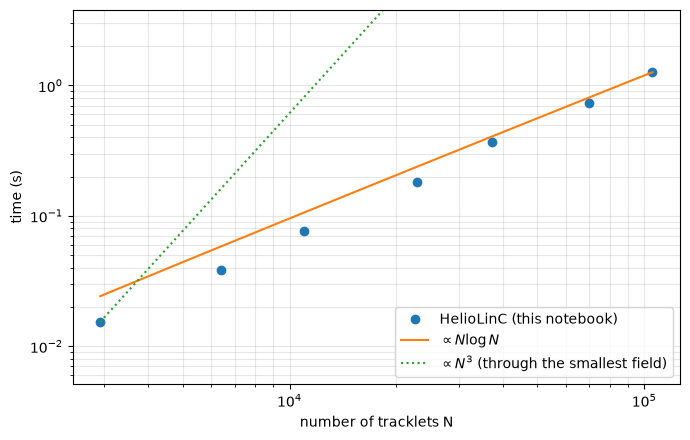

Fitted power law: time ~ N^1.24
N grows by a factor 36; time by 82; N^3 by 46772


In [13]:
sizes, times = [], []
for half_deg in [1, 1.5, 2, 3, 4, 6, 8]:
    d_s = hl.simulate_survey(ORBITS, NIGHTS, (LAM0, 0.0, np.tan(half_deg * DEG)), seed=3)
    t0 = time.perf_counter()
    cl = hl.run_heliolinc(d_s, T_C, G0, GAMMA_DOTS, 1e-3, D_T)
    times.append(time.perf_counter() - t0)
    sizes.append(d_s["tracklet"].max() + 1)
    print(f"field {2 * half_deg:4.0f} deg: {sizes[-1]:7d} tracklets, {len(cl):6d} clusters, {times[-1]:6.2f} s")
sizes, times = np.array(sizes), np.array(times)
slope = np.polyfit(np.log(sizes), np.log(times), 1)[0]

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.loglog(sizes, times, "o", label="HelioLinC (this notebook)")
n = np.geomspace(sizes.min(), sizes.max(), 50)
ax.loglog(n, times[-1] * (n * np.log(n)) / (sizes[-1] * np.log(sizes[-1])), "-", label=r"$\propto N\log N$")
ax.loglog(n, times[0] * (n / sizes[0]) ** 3, ":", label=r"$\propto N^3$ (through the smallest field)")
ax.set_ylim(times.min() / 3, times.max() * 3)
ax.set_xlabel("number of tracklets N"); ax.set_ylabel("time (s)"); ax.legend(); ax.grid(alpha=0.3, which="both")
plt.tight_layout(); plt.show()
print(f"Fitted power law: time ~ N^{slope:.2f}")
print(f"N grows by a factor {sizes[-1] / sizes[0]:.0f}; time by {times[-1] / times[0]:.0f}; N^3 by {(sizes[-1] / sizes[0]) ** 3:.0f}")

**Figure 9.** Time for the transformation and clustering as the field grows from 2° to 16° across, at constant density. The measured time grows close to linearly with the number of tracklets, as H18's $\mathcal{O}(N\log N)$ argument predicts. A cost growing as $N^3$, drawn through the smallest field for comparison, leaves the plot almost at once: over the range shown it would grow by a factor of tens of thousands, against the factor of about 70 measured. H18 note that their algorithm carries a large but fixed prefactor (one transformation per tracklet per hypothesis), and that it parallelises trivially over sky regions and hypotheses.

## 8. Beyond the paper: false tracklets

H18 tested HelioLinC on data with few false detections, and left "a detailed analysis of the influence of false detections" to future work. Real surveys produce many false tracklets: noise, artefacts and pairs of unrelated detections. As a simple experiment, which is not in H18, we add false tracklets placed at random in the field on random nights, each moving at a sky rate drawn from those of the real tracklets. We add them in numbers equal to one and three times the number of real tracklets.

done in 33 s


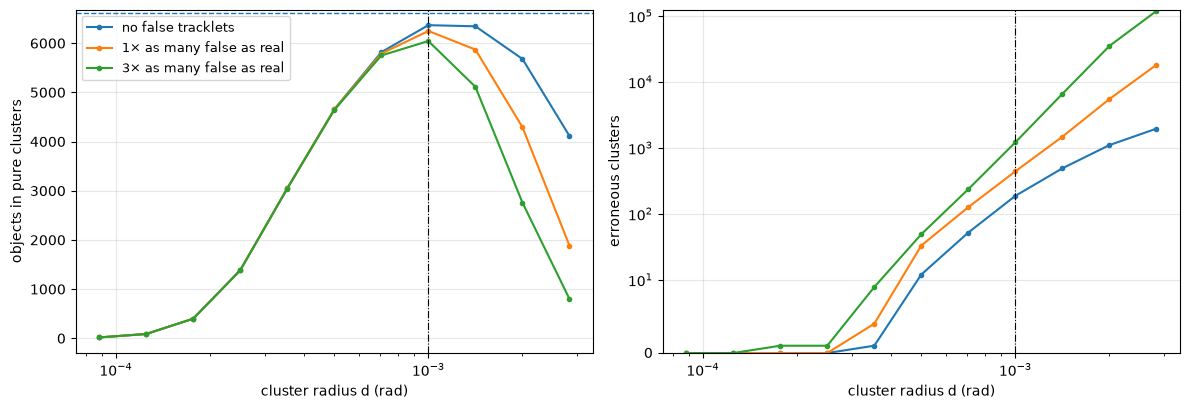

false/real = 0: at d = 1.0e-03, pure objects 6366, valid objects 6431, erroneous 187; most pure objects (6366) at d = 1.0e-03
false/real = 1: at d = 1.0e-03, pure objects 6248, valid objects 6431, erroneous 440; most pure objects (6248) at d = 1.0e-03
false/real = 3: at d = 1.0e-03, pure objects 6043, valid objects 6432, erroneous 1212; most pure objects (6043) at d = 1.0e-03


In [14]:
D_FALSE = D_GRID[D_GRID <= 3e-3]
FALSE = {}
t0 = time.time()
for ratio in [0, 1, 3]:
    d_f = hl.add_false_tracklets(det, ratio * len(tr["obj"]), FIELD, NIGHTS) if ratio else det
    tr_f = hl.tracklet_table(d_f)
    arrows = hl.all_arrows(d_f, T_C, G0, GAMMA_DOTS, z_dir=P0["frame"][2])
    FALSE[ratio] = [hl.score(hl.cluster_arrows(arrows, d, D_T), tr_f["obj"]) for d in D_FALSE]
print(f"done in {time.time() - t0:.0f} s")

fig, axs = plt.subplots(1, 2, figsize=(12, 4.2), sharex=True)
for ratio, sc in FALSE.items():
    lab = "no false tracklets" if ratio == 0 else f"{ratio}× as many false as real"
    axs[0].plot(D_FALSE, [s["pure_objects"] for s in sc], "o-", ms=3, label=lab)
    axs[1].plot(D_FALSE, [s["erroneous"] for s in sc], "o-", ms=3)
axs[0].axhline(len(FINDABLE), color="C0", ls="--", lw=1)
axs[0].set_ylabel("objects in pure clusters"); axs[1].set_ylabel("erroneous clusters")
axs[1].set_yscale("symlog", linthresh=10); axs[1].set_ylim(bottom=0)
for ax in axs:
    ax.set_xscale("log"); ax.set_xlabel("cluster radius d (rad)"); ax.grid(alpha=0.3); ax.axvline(1e-3, color="k", ls="-.", lw=0.8)
axs[0].legend(fontsize=9)
plt.tight_layout(); plt.show()
k = int(np.argmin(np.abs(D_FALSE - 1e-3)))
for ratio, sc in FALSE.items():
    j = int(np.argmax([x["pure_objects"] for x in sc]))
    print(f"false/real = {ratio}: at d = {D_FALSE[k]:.1e}, pure objects {sc[k]['pure_objects']}, "
          f"valid objects {sc[k]['valid_objects']}, erroneous {sc[k]['erroneous']}; "
          f"most pure objects ({sc[j]['pure_objects']}) at d = {D_FALSE[j]:.1e}")

**Figure 10.** Objects found in pure clusters (left) and erroneous clusters (right), with no false tracklets and with one or three false tracklets per real one ($d_t = 5$ days, H18's main-belt grid).

False tracklets do two kinds of damage:
- **Interlopers.** They join real clusters, turning pure clusters into valid ones, which then need orbit fitting to clean.
- **Chance alignments.** They line up with each other or with real tracklets to make erroneous clusters, especially at larger radii.

At $d = 10^{-3}$ rad, three false tracklets per real one cost about 5% of the pure clusters but multiply the erroneous clusters about sixfold (printed above). The best radius stays at $10^{-3}$ rad on our grid, but the penalty for choosing too large a radius grows quickly with contamination. H18 met the same trade-off in the noisier Isolated Tracklet File, where they chose a smaller radius than for their training data. In a real system, the verification steps of H18 Section 5 (cleaning clusters, then orbit fitting) are what turn these candidates into reliable links.

## Summary

* The distance from the observer to an asteroid is unknown and changes quickly, but its heliocentric distance is slowly varying and has a known range. HelioLinC asserts a heliocentric distance and radial velocity, $(\gamma, \dot\gamma)$, and transforms every tracklet into an "arrow" at a common reference time (H18 Eq. 6). Tracklets of the same asteroid then coincide.
* For (10606) Crocco, the arrows from nine nights agree to about 100″, half our cluster radius, even when its distance is assumed to be 2.5 au rather than 3.3 au. Errors in $\gamma$ are largely absorbed by $\dot\alpha$, and a coarse grid of $\dot\gamma$ suffices (H18 Figures 1, 2).
* Clustering the arrows with a KD-tree links the tracklets of thousands of real asteroid orbits in a simulated month of survey data. About 96% of the findable objects are recovered in pure clusters at our best radius, with the same dependence on the hyperparameters as H18's Figure 5. Our best radius is half H18's, a difference between the data sets.
* The standard main-belt search also finds about half of the NEOs and most Hildas and Trojans. Tailored values of $\gamma$ find more (H18 Figures 7, 8).
* The cost grows close to linearly with the number of tracklets, as H18's $\mathcal{O}(N\log N)$ argument predicts.
* Two results differ from H18: our optimal cluster radius, and the fraction of main-belt tracklets in H18's rate box. Both depend on the data set, and we explain both.

## Going further

* **Gravity models.** Try H18's other gravity options (Section 2.1), such as the full Kepler step, which would allow linking over longer windows, across lunations.
* **Six-parameter refits.** Refit each cluster in all six parameters, letting $\gamma$ and $\dot\gamma$ vary (H18 Section 5.2.1), and see how many valid clusters can be cleaned to pure ones.
* **Survey realism.** Make the survey more realistic: tracklets near quadrature, with a variable cadence or weather losses. H18 flag detection biases away from opposition as an open question.
* **Single detections.** H18's discussion suggests generalising the method to single detections by also searching over $\dot\alpha, \dot\beta$, like image-stacking searches. Holman et al. (2019) presented an extension of HelioLinC to sparse single detections. Stetzler et al. (2025) describe a related shift-and-stack algorithm that works on detection catalogues.
* **Applications and other approaches.** Kurlander et al. (2025) presented a HelioLinC survey for Centaurs in Pan-STARRS1 data. Tonry (2023) describes a different approach to linking sky-plane observations.

## References

* Bernstein, G. & Khushalani, B. 2000, *Orbit Fitting and Uncertainties for Kuiper Belt Objects*, AJ 120, 3323. [ADS](https://ui.adsabs.harvard.edu/abs/2000AJ....120.3323B/abstract)
* Bowell, E., Hapke, B., Domingue, D., et al. 1989, *Application of photometric models to asteroids*, in Asteroids II, 524. [ADS](https://ui.adsabs.harvard.edu/abs/1989aste.conf..524B/abstract)
* Curtin, R. R., March, W. B., Ram, P., et al. 2013, *Tree-Independent Dual-Tree Algorithms*, arXiv:1304.4327. [ADS](https://ui.adsabs.harvard.edu/abs/2013arXiv1304.4327C/abstract)
* Holman, M. J., Payne, M. J., Blankley, P., Janssen, R. & Kuindersma, S. 2018, *HelioLinC: A Novel Approach to the Minor Planet Linking Problem*, AJ 156, 135. [ADS](https://ui.adsabs.harvard.edu/abs/2018AJ....156..135H/abstract)
* Holman, M. J., Payne, M. J., Gerdes, D., Lin, H.-W. & Steckler, K. 2019, *Extending the HelioLinC algorithm to sparse single detections*, AAS Meeting 233, 313.04. [ADS](https://ui.adsabs.harvard.edu/abs/2019AAS...23331304H/abstract)
* Jones, R. L., Slater, C. T., Moeyens, J., et al. 2018, *The Large Synoptic Survey Telescope as a Near-Earth Object discovery machine*, Icarus 303, 181. [ADS](https://ui.adsabs.harvard.edu/abs/2018Icar..303..181J/abstract)
* Kurlander, J., Holman, M., Bernardinelli, P., et al. 2025, *A Well-Characterized HelioLinC Survey for Centaurs in Pan-STARRS1*, AAS Meeting 245, 414.08. [ADS](https://ui.adsabs.harvard.edu/abs/2025AAS...24541408K/abstract)
* Meeus, J. 1998, *Astronomical Algorithms*, 2nd ed. (Willmann-Bell), Chapter 49 (dates of new moon).
* Minor Planet Center, *MPCORB.DAT*, the orbit database. [minorplanetcenter.net](https://minorplanetcenter.net/iau/MPCORB.html)
* Standish, E. M. & Williams, J. G., *Approximate Positions of the Planets*, JPL Solar System Dynamics. [ssd.jpl.nasa.gov](https://ssd.jpl.nasa.gov/planets/approx_pos.html)
* Stetzler, S., et al. 2025, *An Efficient Shift-and-stack Algorithm Applied to Detection Catalogs*, AJ 170, 352. [ADS](https://ui.adsabs.harvard.edu/abs/2025AJ....170..352S/abstract)
* Tonry, J. L. 2023, *Linking Sky-plane Observations of Moving Objects*, PASP 135, 114502. [ADS](https://ui.adsabs.harvard.edu/abs/2023PASP..135k4502T/abstract)